## Student Exam Performance Prediction Using Machine Learning

### Project Overview
This project explores the use of machine learning to predict students' mathematics examination scores using selected demographic and educational characteristics.

### Project Aim
To develop and evaluate regression models for predicting students' mathematics scores.

### Objectives
1. Explore and analyse the student performance dataset.
2. Identify patterns and relationships between student characteristics and examination scores.
3. Prepare and preprocess the data for machine learning.
4. Train and evaluate four regression algorithms.
5. Compare model performance and identify limitations.

![image](books.jpg)

In [1345]:
# Importing Libraries 
import pandas as pd 
import numpy as np
#Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import preprocessing tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from warnings import filterwarnings
filterwarnings('ignore')


### Understanding the Data Set

In [1346]:
# Read the csv file
student_data = pd.read_csv('StudentsPerformance.csv')
student_data.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [1347]:
student_data.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [1348]:
student_data.shape

(1000, 8)

In [1349]:
student_data.columns


Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')

In [1350]:
student_data.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [1351]:
student_data.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [1352]:
student_data.duplicated().sum()

np.int64(0)

### Exploratory Data Analysis (EDA)

#### Categorical Univariate Analysis

In [1353]:
# Examine student gender
student_data['gender'].value_counts()

gender
female    518
male      482
Name: count, dtype: int64

In [1354]:
student_data['gender'].value_counts(normalize=True) * 100

gender
female    51.8
male      48.2
Name: proportion, dtype: float64

- Female students account for 51.8% of the dataset.
- Male students account for 48.2%.
- The dataset has a fairly balanced gender distribution.
- There are 36 more female students than male students.

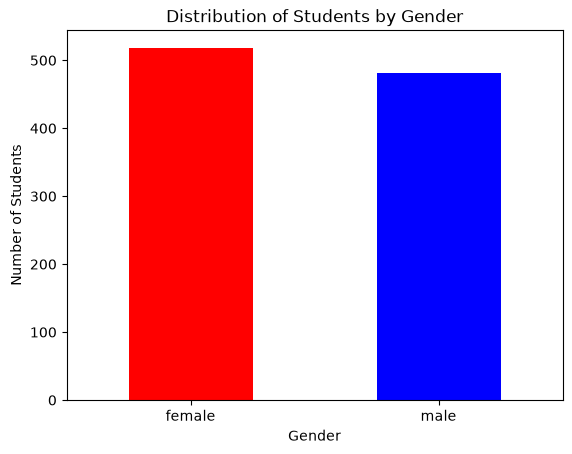

In [1355]:
# Visualize this results 

gender_counts = student_data['gender'].value_counts()
gender_counts.plot(kind='bar', color=['red','blue'])

plt.title('Distribution of Students by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Students')
plt.xticks(rotation=0)

plt.show()

In [1356]:
# Examine Parental level of education
student_data['parental level of education'].value_counts()

parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

In [1357]:
student_data['parental level of education'].value_counts(normalize=True) * 100

parental level of education
some college          22.6
associate's degree    22.2
high school           19.6
some high school      17.9
bachelor's degree     11.8
master's degree        5.9
Name: proportion, dtype: float64

- Some college is the most common parental education category, representing 22.6%.
- Associate's degree follows closely at 22.2%.
- Only 5.9% of students have parents with master's degrees, making it the least common category.
- Approximately 42.2% of students have parents whose education is recorded as high school or some high school.

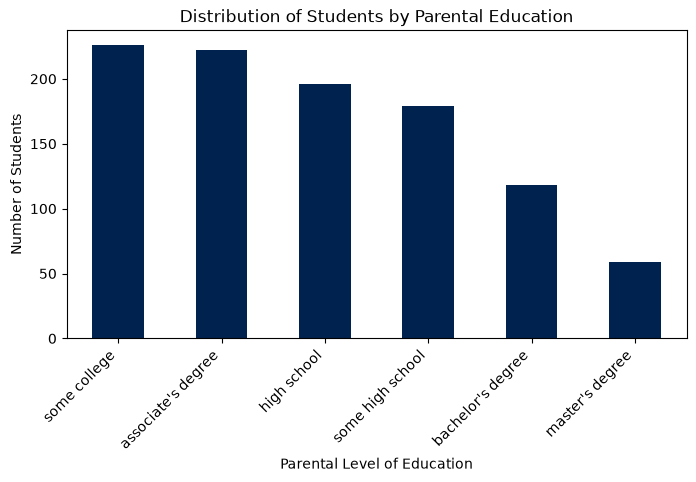

In [1358]:
#Visualize Parental level of education
parent_education = student_data['parental level of education'].value_counts()
parent_education.plot(kind='bar',colormap='cividis', figsize=(8,4))


plt.title('Distribution of Students by Parental Education')
plt.xlabel('Parental Level of Education')
plt.ylabel('Number of Students')
plt.xticks(rotation=45, ha='right')

plt.show()



In [1359]:
#Analyse test preparation course

student_data['test preparation course'].value_counts()

test preparation course
none         642
completed    358
Name: count, dtype: int64

In [1360]:
preparation_course = student_data['test preparation course'].value_counts(normalize=True) * 100
preparation_course

test preparation course
none         64.2
completed    35.8
Name: proportion, dtype: float64

- 642 students (64.2%) did not complete a test preparation course.
- 358 students (35.8%) completed a test preparation course.
- The majority of students did not take the preparation course.
- There is a difference of 284 students between the two categories.

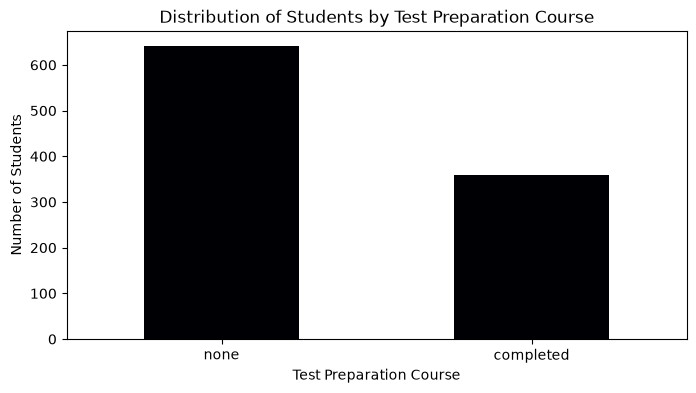

In [1361]:
# Visualize the test prepartion course
preparation_course = student_data['test preparation course'].value_counts()
preparation_course.plot(kind='bar',colormap='inferno',figsize=(8,4))

plt.title('Distribution of Students by Test Preparation Course')
plt.xlabel('Test Preparation Course')
plt.ylabel('Number of Students')
plt.xticks(rotation=0)

plt.show()

In [1362]:
# Analyse lunch type
student_data['lunch'].value_counts()

lunch
standard        645
free/reduced    355
Name: count, dtype: int64

In [1363]:

lunch_type = student_data['lunch'].value_counts(normalize=True)* 100
lunch_type

lunch
standard        64.5
free/reduced    35.5
Name: proportion, dtype: float64

- 645 students (64.5%) receive standard lunch.
- 355 students (35.5%) receive free or reduced-price lunch.
- The majority of students fall under the standard lunch category.
- The difference between the two groups is 290 students.

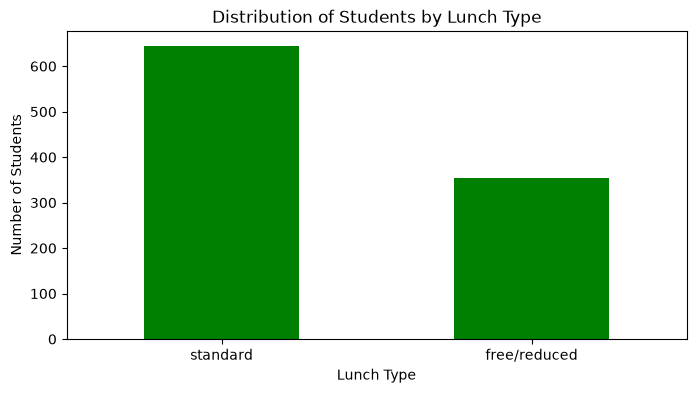

In [1364]:
# Visualize Lunch type
lunch_type = student_data['lunch'].value_counts()
lunch_type.plot(kind = 'bar',color = 'green', figsize=(8,4))

plt.title('Distribution of Students by Lunch Type')
plt.xlabel('Lunch Type')
plt.ylabel('Number of Students')
plt.xticks(rotation=0)

plt.show()

In [1365]:
#  Race and Ethnicity
student_data['race/ethnicity'].value_counts()


race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

In [1366]:
race = student_data['race/ethnicity'].value_counts(normalize=True)* 100
race

race/ethnicity
group C    31.9
group D    26.2
group B    19.0
group E    14.0
group A     8.9
Name: proportion, dtype: float64

- Group C has the highest representation, with 319 students (31.9%).
- Group D follows with 262 students (26.2%).
- Group A has the lowest representation, with 89 students (8.9%).
- Groups C and D together account for 58.1% of the dataset.

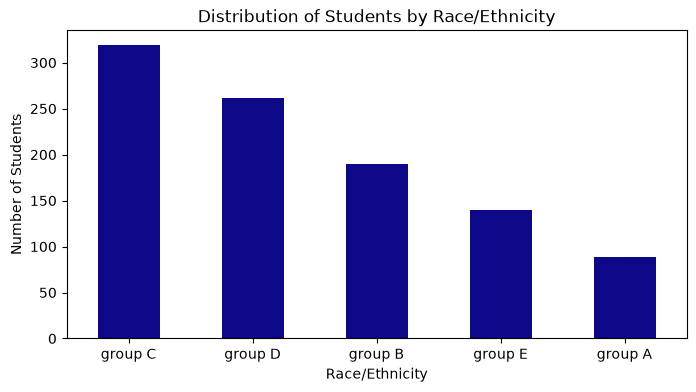

In [1367]:
# Visualize the race/ethnicity
race = student_data['race/ethnicity'].value_counts()
race.plot(kind='bar',colormap = 'plasma', figsize=(8,4))

plt.title('Distribution of Students by Race/Ethnicity')
plt.xlabel('Race/Ethnicity')
plt.ylabel('Number of Students')
plt.xticks(rotation=0)

plt.show()

#### Numerical Univariate Analysis

Our three numerical variables are:
1. Math score
2. Reading score
3. Writing score

In [1368]:
#Descriptive statistics
student_data[['math score','reading score','writing score']].describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


From the descriptive statistics:
1. Reading has the highest average and median score.
2. Mathematics has the lowest average score.
3. Score variability is relatively similar across the three subjects.
4. Mathematics contains at least one zero score that deserves further investigation.

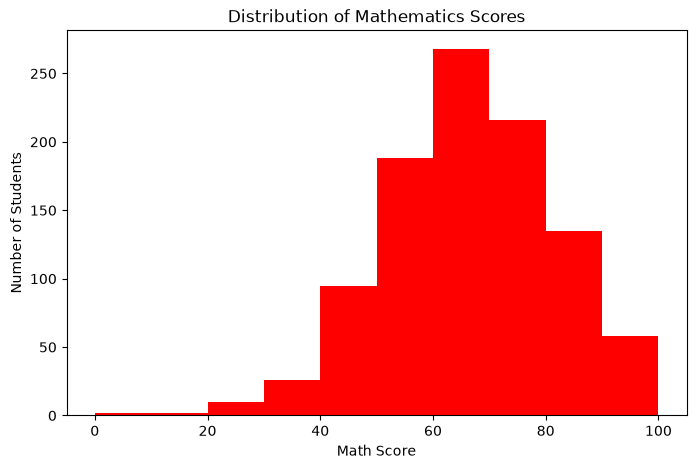

In [1369]:
# Visualize using histogram

plt.figure(figsize=(8, 5))

plt.hist(
    student_data['math score'],
    color='red',
    bins=10
)

plt.title('Distribution of Mathematics Scores')
plt.xlabel('Math Score')
plt.ylabel('Number of Students')

plt.show()

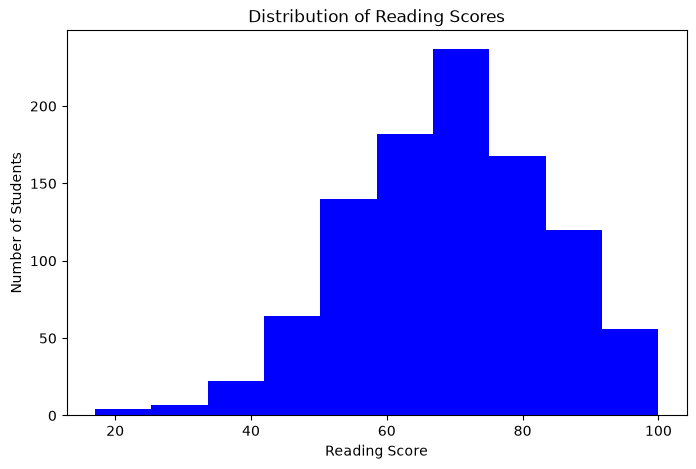

In [1370]:
plt.figure(figsize=(8,5))

plt.hist(
    student_data['reading score'],
    color='blue',
    bins=10
    )

plt.title('Distribution of Reading Scores')
plt.xlabel('Reading Score')
plt.ylabel('Number of Students')

plt.show()

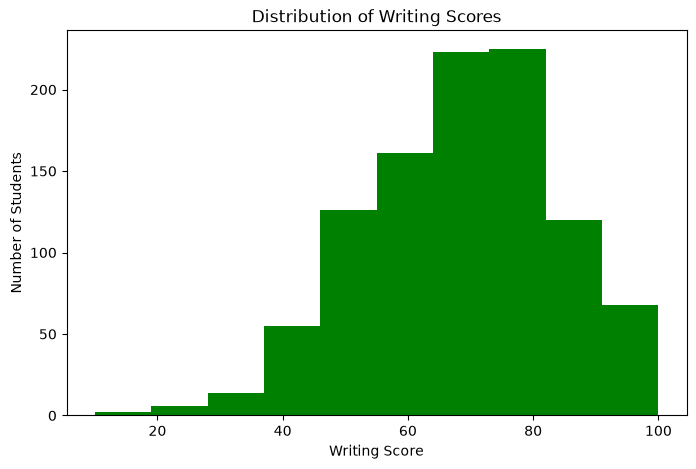

In [1371]:
plt.figure(figsize=(8,5))

plt.hist(
     student_data['writing score'],
     color = 'green',
     bins=10

)

plt.title('Distribution of Writing Scores')
plt.xlabel('Writing Score')
plt.ylabel('Number of Students')

plt.show()

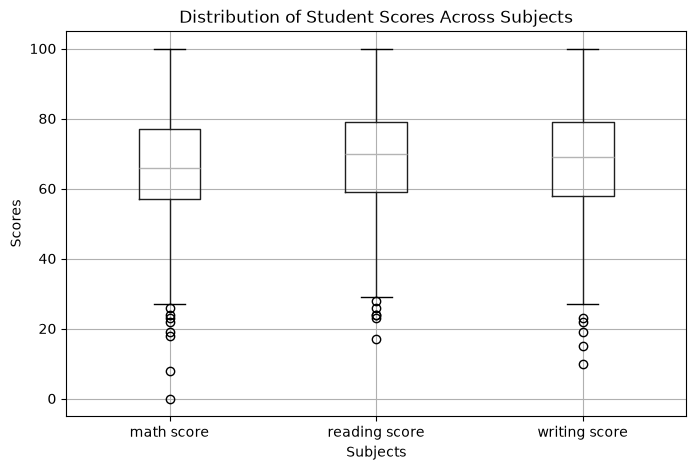

In [1372]:
plt.figure(figsize=(8,5))
student_data[['math score','reading score','writing score']].boxplot()

plt.title('Distribution of Student Scores Across Subjects')
plt.xlabel('Subjects')
plt.ylabel('Scores')

plt.show()

### Univariate Analysis – Conclusion

The analysis revealed that:

- The dataset contains slightly more female students (51.8%) than male students (48.2%).
- Some college was the most common parental education category (22.6%).
- Most students had not completed a test preparation course (64.2%).
- Most students received standard lunch (64.5%).
- Group C had the highest representation (31.9%).
- Reading had the highest average score (69.17), followed by writing (68.05) and mathematics (66.09).
- The score distributions appeared left-skewed, with potential low-score outliers in all three subjects.

Overall, students performed slightly better in reading and writing than in mathematics. Further analysis is needed to investigate relationships between student characteristics and academic performance.

## Bivariate Analysis

#### 1. Test Preparation Course vs Academic Performance
Why are we investigating this?

We want to establish whether students who completed a test preparation course achieved different average scores from students who did not complete the course.

In [1373]:
#Calculate the average scores for each group.

student_data.groupby('test preparation course')[
    ['math score', 'reading score', 'writing score']
].mean()

,math score,reading score,writing score
test preparation course,,,
completed,69.695531,73.893855,74.418994
none,64.077882,66.534268,64.504673


### Conclusion

The analysis shows that students who completed the test preparation course
achieved higher average scores than those who did not complete the course
across all three subjects.

The largest difference was observed in writing (9.91 points), followed by
reading (7.36 points) and mathematics (5.62 points).

These findings suggest a positive association between completing a test
preparation course and academic performance. However, this analysis does
not establish that the course alone caused the higher scores.

#### 2. Gender vs Academic Performance

The purpose of this analysis is to investigate whether male and female students have different average academic scores across the three subjects.

In [1374]:
student_data.groupby('gender')[
['math score','writing score','reading score']

].mean()





,math score,writing score,reading score
gender,,,
female,63.633205,72.467181,72.608108
male,68.728216,63.311203,65.473029


### Conclusion

The analysis revealed differences in average academic performance
between male and female students.

Male students achieved a higher average score in mathematics,
while female students achieved higher average scores in reading
and writing.

The largest difference was observed in writing, where female
students scored approximately 9.16 points higher than male students.

These findings suggest an association between gender and academic
performance in the dataset. However, they do not establish that
gender causes differences in academic performance.

#### 3. Parental Level of Education vs Academic Performance
In this analysis, we want to investigate whether students whose parents have different levels of education achieve different average academic scores.

In [1375]:
student_data.groupby('parental level of education')[
    ['math score','writing score','reading score']
].mean()

,math score,writing score,reading score
parental level of education,,,
associate's degree,67.882883,69.896396,70.927928
bachelor's degree,69.389831,73.381356,73.000000
high school,62.137755,62.448980,64.704082
master's degree,69.745763,75.677966,75.372881
some college,67.128319,68.840708,69.460177
some high school,63.497207,64.888268,66.938547


### Conclusion

The analysis revealed differences in academic performance across
the various parental education groups.

Students whose parents had a master's degree recorded the highest
average scores in mathematics, reading and writing.

Conversely, students whose parents had completed high school
recorded the lowest average scores across all three subjects.

These findings suggest an association between parental education
level and student academic performance. However, further analysis
is required to establish the influence of other contributing factors.

#### 4. Lunch Type vs Academic Performance

We will investigate whether students receiving standard lunch and those receiving free/reduced lunch have different average academic scores.

In [1376]:
student_data.groupby('lunch')[
['math score','reading score','writing score']
].mean()

,math score,reading score,writing score
lunch,,,
free/reduced,58.921127,64.653521,63.022535
standard,70.034109,71.654264,70.823256


### Conclusion

The analysis revealed noticeable differences in academic performance
between students receiving standard lunch and those receiving
free/reduced lunch.

Students receiving standard lunch achieved higher average scores
across mathematics, reading and writing.

The largest difference was observed in mathematics (11.11 points),
followed by writing (7.80 points) and reading (7.00 points).

These findings suggest an association between lunch category and
academic performance. Further analysis is needed to investigate
whether socioeconomic circumstances or other factors contribute
to these differences.

#### 5. Race/Ethnicity Group vs Academic Performance

We will investigate whether average academic performance differs across the five groups represented in the dataset.

In [1377]:
student_data.groupby('race/ethnicity')[
    ['math score', 'reading score', 'writing score']
].mean()

,math score,reading score,writing score
race/ethnicity,,,
group A,61.629213,64.674157,62.674157
group B,63.452632,67.352632,65.600000
group C,64.463950,69.103448,67.827586
group D,67.362595,70.030534,70.145038
group E,73.821429,73.028571,71.407143


### Conclusion

The analysis revealed differences in average academic performance
across the five race/ethnicity groups.

Group E recorded the highest average scores in mathematics,
reading and writing, while Group A recorded the lowest averages
across all three subjects.

The average scores generally increased from Group A to Group E.

These findings indicate an association between group membership
and academic performance in this dataset. However, they do not
establish causation or explain why these differences exist.

## Numerical Variables vs Numerical Variables
we want to investigate whether students who perform well in one subject also tend to perform well in another subject.
Understanding these relationships can help us identify patterns between academic subjects.

#### Mathematics vs Reading Scores

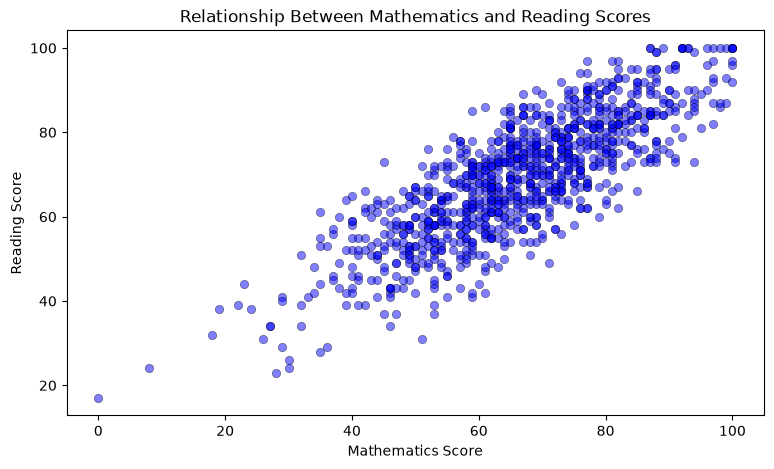

In [1378]:
# Scatter plot 
plt.figure(figsize=(9,5))

plt.scatter(
    student_data['math score'],
    student_data['reading score'],
    color='blue',
    edgecolor='black',
    linewidth=0.5,
    alpha=0.5

)
plt.title('Relationship Between Mathematics and Reading Scores')
plt.xlabel('Mathematics Score')
plt.ylabel('Reading Score')

plt.show()

### Conclusion

The scatter plot reveals a strong positive relationship between
mathematics and reading scores.

Students with higher mathematics scores generally tend to achieve
higher reading scores, while students with lower mathematics scores
generally tend to have lower reading scores.

However, the relationship is not perfect because students with
similar mathematics scores can have different reading scores.

Further analysis using correlation will help quantify the strength
and direction of this relationship.

In [1379]:
# Calculate Pearson correlation
student_data['math score'].corr(
    student_data['reading score']
)

np.float64(0.8175796636720541)

### Conclusion

The Pearson correlation coefficient between mathematics and reading
scores was approximately 0.818.

This indicates a strong positive linear relationship between the
two subjects. Students with higher mathematics scores generally
tend to achieve higher reading scores.

However, correlation does not imply causation, and the relationship
is not perfect.

#### Mathematics vs Reading Scores

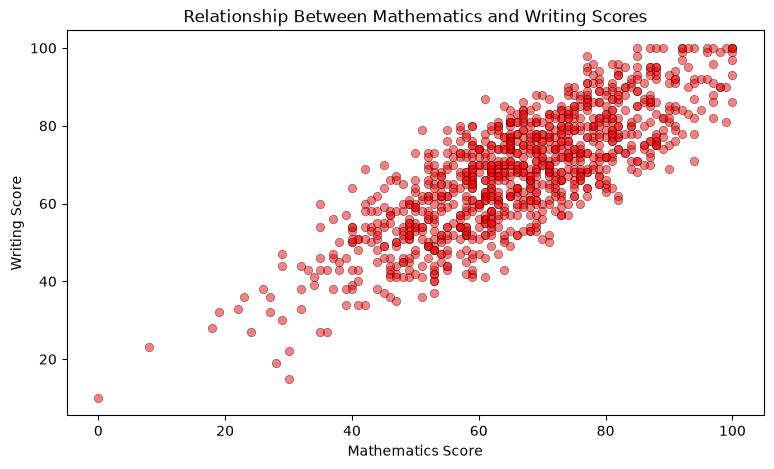

In [1380]:
# Scatter plot 
plt.figure(figsize=(9,5))

plt.scatter(
    student_data['math score'],
    student_data['writing score'],
    color='red',
    edgecolor='black',
    linewidth=0.5,
    alpha=0.5

)
plt.title('Relationship Between Mathematics and Writing Scores')
plt.xlabel('Mathematics Score')
plt.ylabel('Writing Score')

plt.show()

In [1381]:
# Calculate Pearson correlation
student_data['math score'].corr(
    student_data['writing score']
    
)

np.float64(0.8026420459498078)

### Conclusion

The Pearson correlation coefficient between mathematics and writing
scores was approximately 0.803.

This indicates a strong positive linear relationship between the
two subjects. Students with higher mathematics scores generally
tend to achieve higher writing scores.

When compared with mathematics and reading (0.818), the relationship
with reading is slightly stronger.

#### Writing score vs Reading Scores

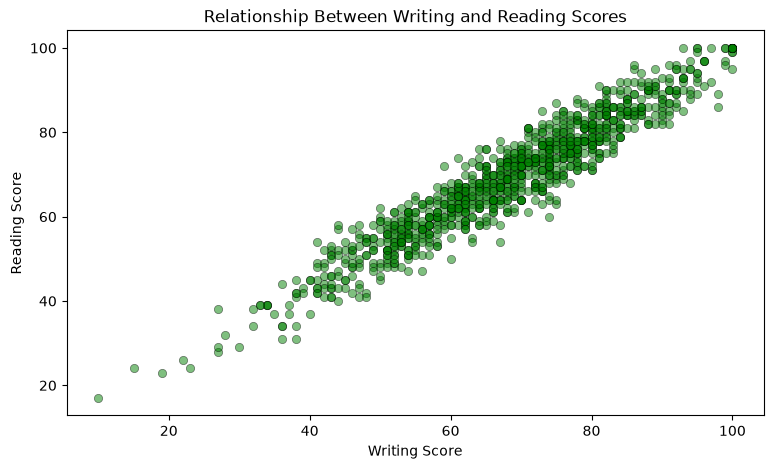

In [1382]:
plt.figure(figsize=(9,5))

plt.scatter(
    student_data['writing score'],
    student_data['reading score'],
    color='green',
    edgecolor= 'black',
    linewidth=0.5,
    alpha=0.5

)
plt.title('Relationship Between Writing and Reading Scores')
plt.xlabel('Writing Score')
plt.ylabel('Reading Score')

plt.show()

In [1383]:
# Calculate Pearson correlation
student_data['writing score'].corr(
    student_data['reading score']
)

np.float64(0.9545980771462476)

### Conclusion: Numerical Bivariate Analysis

The analysis revealed positive linear relationships between all
three academic subjects.

- Mathematics and reading: 0.818
- Mathematics and writing: 0.803
- Reading and writing: 0.955

Reading and writing demonstrated the strongest relationship,
suggesting that students who perform well in reading generally
also perform well in writing.

Mathematics also showed strong positive relationships with both
subjects.

These findings indicate that academic performance across the
three subjects is closely related. However, correlation does not
establish causation.

### Multivariate Analysis

Does the relationship between test preparation and academic performance look similar for both male and female students?

To answer this, we will examine three variables together:
1. Gender
2. Test preparation course
3. Mathematics, reading and writing scores

### Examining gender and test preparation together

In [1384]:
# Group students by gender and test preparation course,
# then calculate the average scores in each group.

student_data.groupby(['gender', 'test preparation course'])[
    ['math score', 'reading score', 'writing score']
].mean()

math score  reading score  writing score
gender test preparation course                                          
female completed                 67.195652      77.375000      78.793478
       none                      61.670659      69.982036      68.982036
male   completed                 72.339080      70.212644      69.793103
       none                      66.688312      62.795455      59.649351

### Multivariate Analysis – Gender and Test Preparation

The analysis examined the relationship between gender, test preparation course completion, and academic performance.

The findings revealed that:

- Students who completed the test preparation course had higher average scores across mathematics, reading, and writing, regardless of gender.
- Among female students, the largest score difference was in writing (9.81 points).
- Among male students, the largest score difference was also in writing (10.14 points).
- The differences in mathematics scores were relatively similar between female and male students.


Overall, completing the test preparation course was associated with higher academic performance across both genders. However, these findings do not establish a causal relationship.

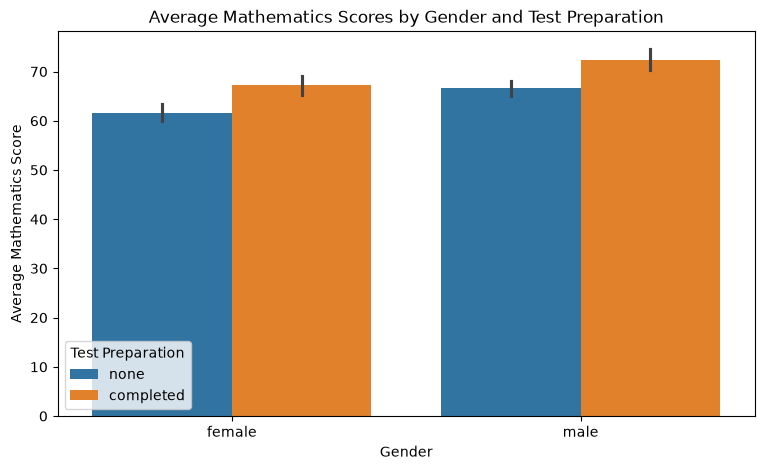

In [1385]:
# Visualize this results 
plt.figure(figsize=(9,5))

sns.barplot(
    data=student_data,
    x='gender',
    y='math score',
    hue='test preparation course'
)

plt.title('Average Mathematics Scores by Gender and Test Preparation')
plt.xlabel('Gender')
plt.ylabel('Average Mathematics Score')
plt.legend(title='Test Preparation')
plt.show()

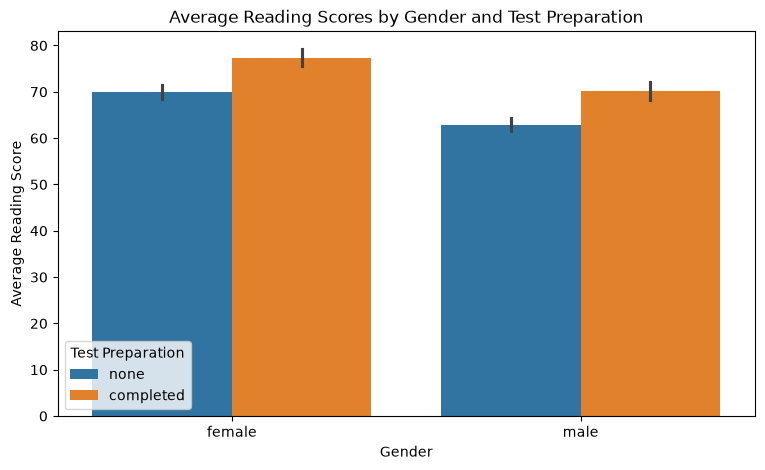

In [1386]:
# Compare average reading scores by gender and test preparation course

plt.figure(figsize=(9, 5))

sns.barplot(
    data=student_data,
    x='gender',
    y='reading score',
    hue='test preparation course'
)

plt.title('Average Reading Scores by Gender and Test Preparation')
plt.xlabel('Gender')
plt.ylabel('Average Reading Score')
plt.legend(title='Test Preparation')
plt.show()

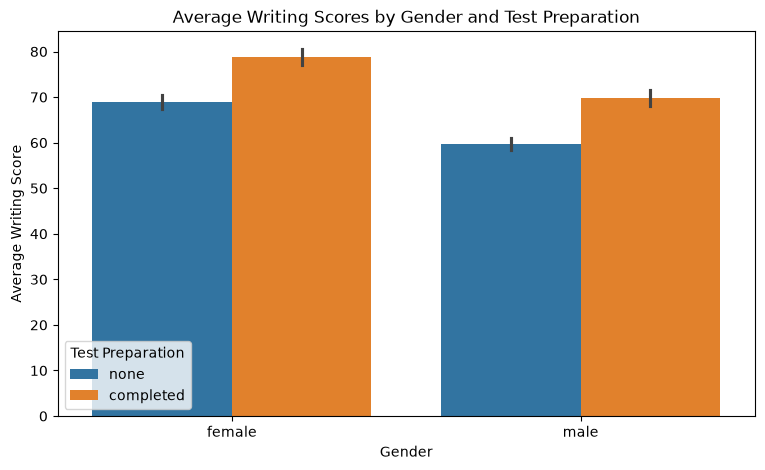

In [1387]:
# Compare average writing scores by gender and test preparation course

plt.figure(figsize=(9, 5))

sns.barplot(
    data=student_data,
    x='gender',
    y='writing score',
    hue='test preparation course'
)

plt.title('Average Writing Scores by Gender and Test Preparation')
plt.xlabel('Gender')
plt.ylabel('Average Writing Score')
plt.legend(title='Test Preparation')
plt.show()

### Visual Analysis – Gender, Test Preparation and Academic Performance

The grouped bar charts provided a visual comparison of academic performance across gender and test preparation categories.

The findings showed that:

- Students who completed the test preparation course had higher average scores in all three subjects, regardless of gender.
- Male students recorded higher average mathematics scores than female students.
- Female students recorded higher average reading and writing scores than male students.
- The difference between students who completed and did not complete preparation was particularly noticeable in writing.

Overall, test preparation completion was consistently associated with higher average academic performance across both gender groups.

### Parental Education, Test Preparation and Academic Performance

In [1388]:
# Group students by parental education and test preparation course
# Calculate the average score in each subject

student_data.groupby([
    'parental level of education',
    'test preparation course'
])[
    ['math score', 'reading score', 'writing score']
].mean()

math score  \
parental level of education test preparation course               
associate's degree          completed                 71.829268   
                            none                      65.571429   
bachelor's degree           completed                 73.282609   
                            none                      66.902778   
high school                 completed                 65.000000   
                            none                      60.992857   
master's degree             completed                 70.600000   
                            none                      69.307692   
some college                completed                 71.454545   
                            none                      64.892617   
some high school            completed                 66.701299   
                            none                      61.078431   

                                                     reading score  \
parental level of education test preparation course                  
associate's degree          completed                    76.170732   
                            none                         67.857143   
bachelor's degree           completed                    76.739130   
                            none                         70.611111   
high school                 completed                    67.839286   
                            none                         63.450000   
master's degree             completed                    78.250000   
                            none                         73.897436   
some college                completed                    75.987013   
                            none                         66.087248   
some high school            completed                    70.948052   
                            none                         63.911765   

                                                     writing score  
parental level of education test preparation course                 
associate's degree          completed                    76.817073  
                            none                         65.842857  
bachelor's degree           completed                    78.695652  
                            none                         69.986111  
high school                 completed                    68.053571  
                            none                         60.207143  
master's degree             completed                    80.100000  
                            none                         73.410256  
some college                completed                    76.519481  
                            none                         64.872483  
some high school            completed                    70.363636  
                            none                         60.754902

### Multivariate Analysis – Parental Education and Test Preparation

The analysis examined the combined relationship between parental education level, test preparation course completion, and academic performance.

The findings revealed that:

- Students who completed the test preparation course recorded higher average scores across all three subjects within every parental education category.
- Students whose parents had a bachelor's degree and who completed preparation recorded the highest mathematics average (73.28).
- Students whose parents had a master's degree and who completed preparation recorded the highest reading (78.25) and writing (80.10) averages.
- Writing generally showed the largest difference between students who completed and did not complete preparation.

Overall, test preparation completion was consistently associated with higher average academic performance across parental education categories. These findings describe associations and do not establish causation.

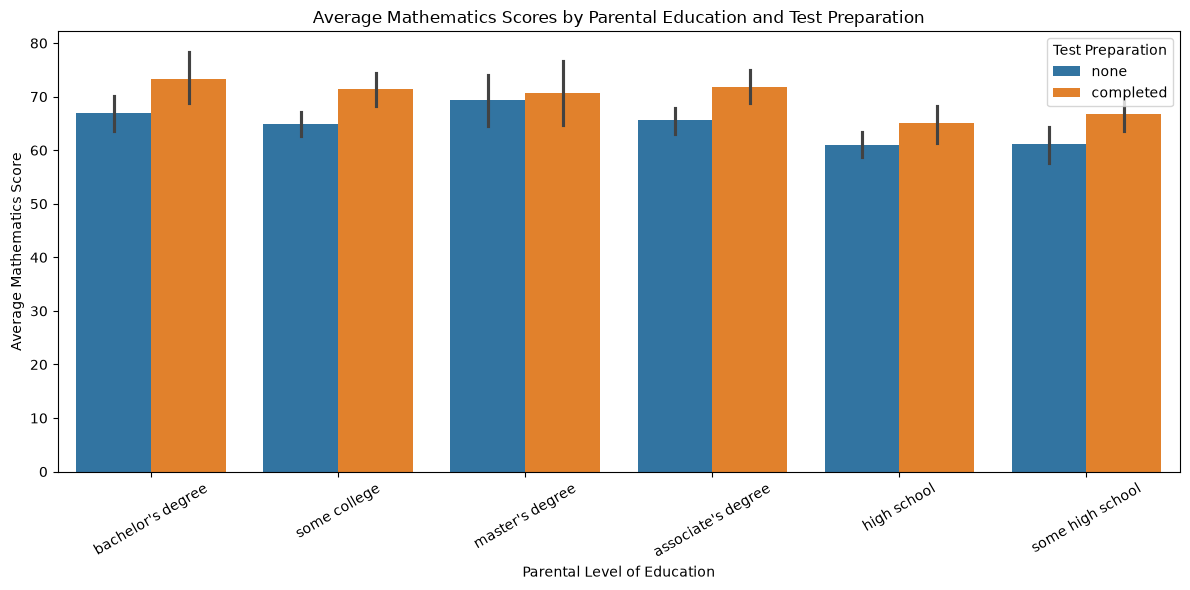

In [1389]:
# Compare average mathematics scores by parental education and test preparation

plt.figure(figsize=(12, 6))

sns.barplot(
    data=student_data,
    x='parental level of education',
    y='math score',
    hue='test preparation course'
)

plt.title('Average Mathematics Scores by Parental Education and Test Preparation')
plt.xlabel('Parental Level of Education')
plt.ylabel('Average Mathematics Score')
plt.xticks(rotation=30)
plt.legend(title='Test Preparation')
plt.tight_layout()
plt.show()

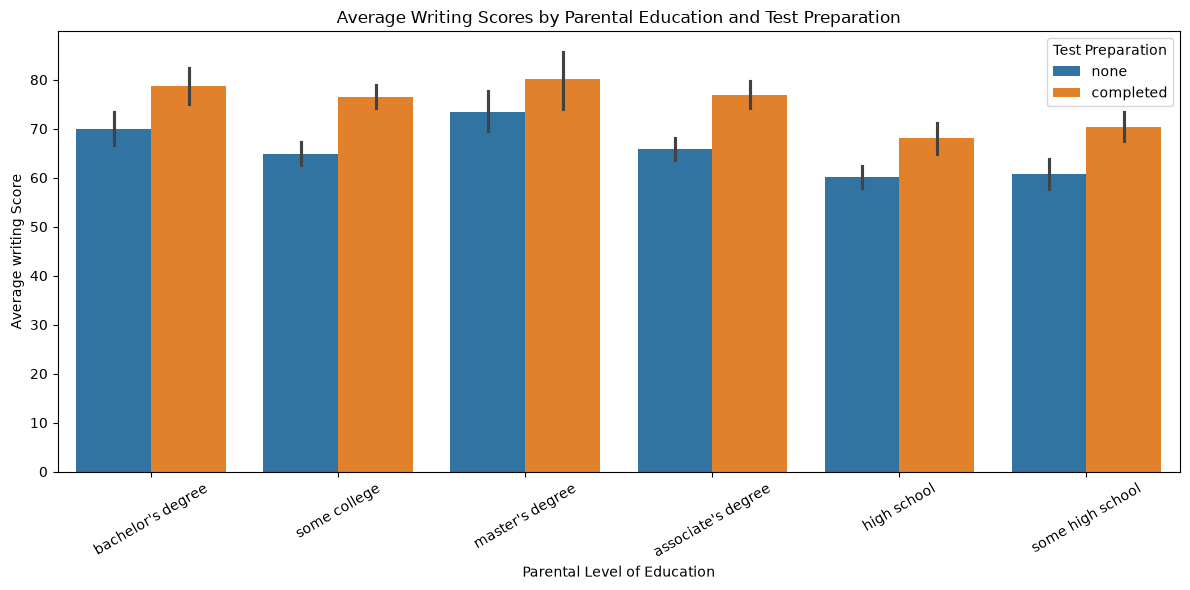

In [1390]:
# Compare average Writing scores by parental education and test preparation

plt.figure(figsize=(12, 6))

sns.barplot(
    data=student_data,
    x='parental level of education',
    y='writing score',
    hue='test preparation course'
)

plt.title('Average Writing Scores by Parental Education and Test Preparation')
plt.xlabel('Parental Level of Education')
plt.ylabel('Average writing Score')
plt.xticks(rotation=30)
plt.legend(title='Test Preparation')
plt.tight_layout()
plt.show()

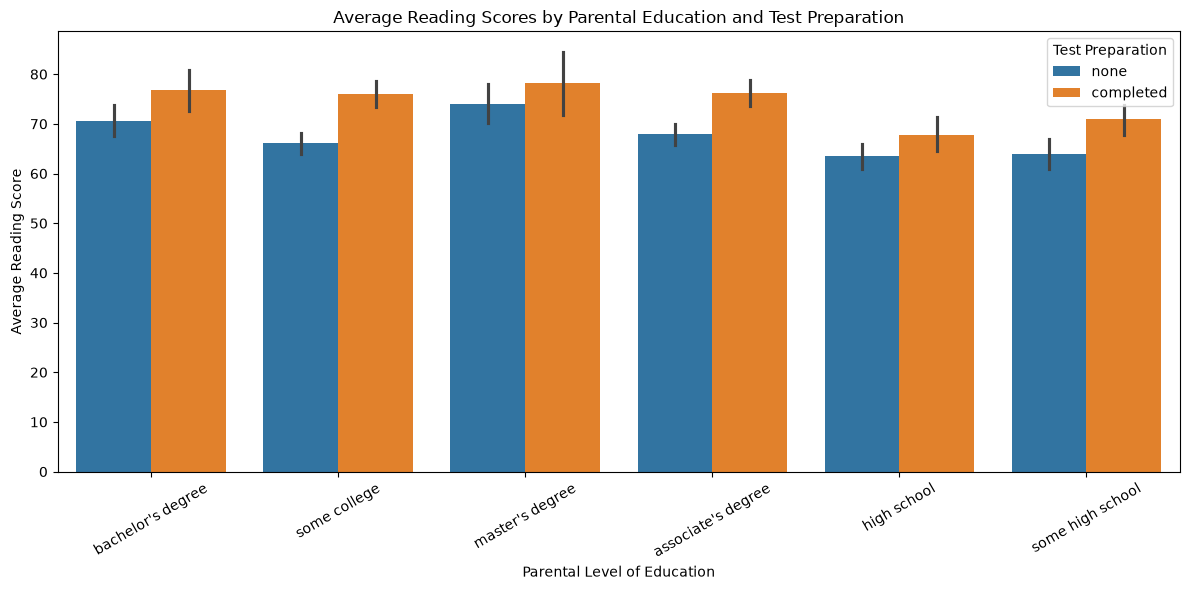

In [1391]:
# Compare average Reading scores by parental education and test preparation

plt.figure(figsize=(12, 6))

sns.barplot(
    data=student_data,
    x='parental level of education',
    y='reading score',
    hue='test preparation course'
)

plt.title('Average Reading Scores by Parental Education and Test Preparation')
plt.xlabel('Parental Level of Education')
plt.ylabel('Average Reading Score')
plt.xticks(rotation=30)
plt.legend(title='Test Preparation')
plt.tight_layout()
plt.show()

### Lunch Type, Test Preparation and Academic Performance

In [1392]:
# Group students by lunch type and test preparation course
# Calculate the average scores in all three subjects

student_data.groupby([
    'lunch',
    'test preparation course'
])[
    ['math score', 'reading score', 'writing score']
].mean()

math score  reading score  writing score
lunch        test preparation course                                          
free/reduced completed                 63.045802      69.870229      70.351145
             none                      56.508929      61.602679      58.736607
standard     completed                 73.533040      76.215859      76.766520
             none                      68.133971      69.177033      67.595694

### Multivariate Analysis – Lunch Type and Test Preparation

The analysis examined the combined relationship between lunch type, test preparation course completion, and academic performance.

The findings revealed that:

- Students receiving standard lunch recorded higher average scores than those receiving free/reduced lunch across all three subjects.
- Students who completed the test preparation course had higher average scores in both lunch categories.
- Writing showed the largest difference between preparation groups: 11.61 points for free/reduced lunch and 9.17 points for standard lunch.
- Differences in academic performance between lunch categories were observed regardless of test preparation status.

Overall, both lunch category and test preparation status were associated with academic performance in this dataset. However, these findings do not establish causation.

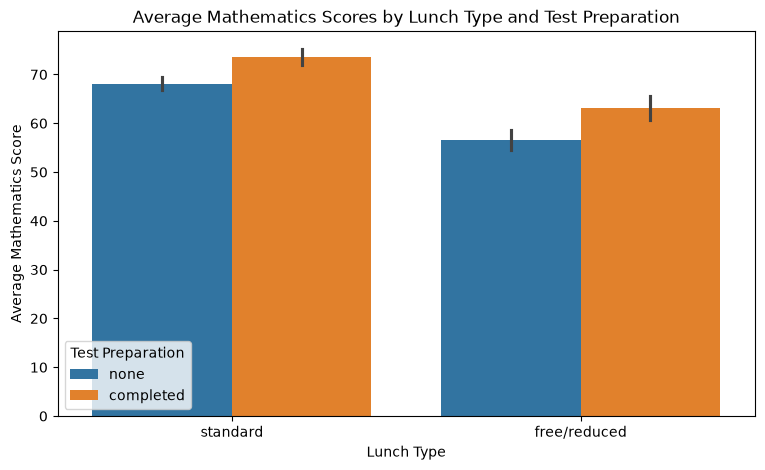

In [1393]:
# Compare average mathematics scores by lunch type and test preparation

plt.figure(figsize=(9, 5))

sns.barplot(
    data=student_data,
    x='lunch',
    y='math score',
    hue='test preparation course'
)

plt.title('Average Mathematics Scores by Lunch Type and Test Preparation')
plt.xlabel('Lunch Type')
plt.ylabel('Average Mathematics Score')
plt.legend(title='Test Preparation')
plt.show()

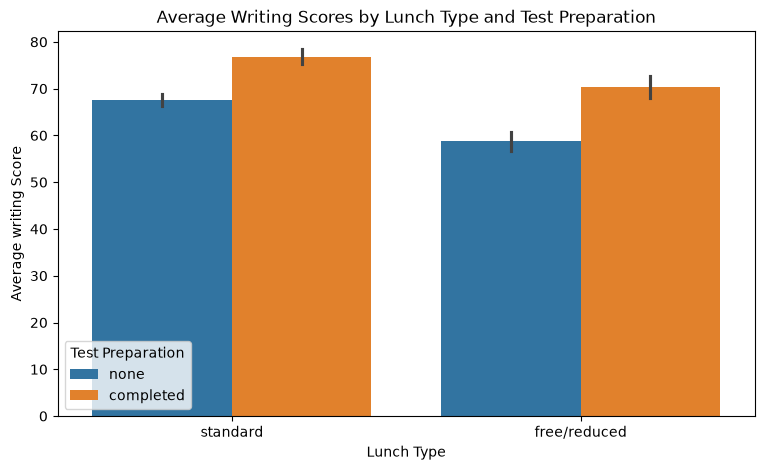

In [1394]:
# Compare average writing scores by lunch type and test preparation

plt.figure(figsize=(9, 5))

sns.barplot(
    data=student_data,
    x='lunch',
    y='writing score',
    hue='test preparation course'
)

plt.title('Average Writing Scores by Lunch Type and Test Preparation')
plt.xlabel('Lunch Type')
plt.ylabel('Average writing Score')
plt.legend(title='Test Preparation')
plt.show()

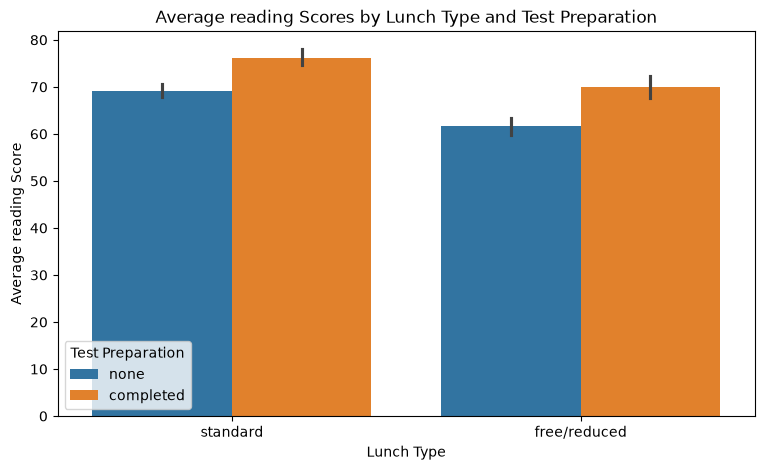

In [1395]:
# Compare average Reading scores by lunch type and test preparation

plt.figure(figsize=(9, 5))

sns.barplot(
    data=student_data,
    x='lunch',
    y='reading score',
    hue='test preparation course'
)

plt.title('Average reading Scores by Lunch Type and Test Preparation')
plt.xlabel('Lunch Type')
plt.ylabel('Average reading Score')
plt.legend(title='Test Preparation')
plt.show()

## Machine Learning – Mathematics Score Prediction

- X (Features): The five student characteristics used for prediction.
- y (Target): The mathematics score we want to predict.

In [1396]:
# Define the input features (X)

X = student_data[
    [
        'gender',
        'race/ethnicity',
        'parental level of education',
        'lunch',
        'test preparation course'
    ]
]

In [1397]:
# Define the target variable (y)

y = student_data['math score']

### Data Preprocessing – Feature Encoding
Understand the data types in our features

In [1398]:
X.dtypes

gender                         str
race/ethnicity                 str
parental level of education    str
lunch                          str
test preparation course        str
dtype: object

Since our features are strings we need to do one Hot encoding to change the data types into 1 and 0

### One Hot Encoding

In [1399]:
# Apply One-Hot Encoding to the gender column

gender_encoded = pd.get_dummies(X['gender'])

# Display the encoded data

display(gender_encoded.head())

,female,male
0,True,False
1,True,False
2,True,False
3,False,True
4,False,True


Why do we need One-Hot Encoding?
Our machine learning model, Linear Regression, works with numerical input. However, our original features contain text such as female, male, standard and free/reduced.

We therefore convert categorical values into numerical representations.

One-Hot Encoding does this without assigning arbitrary numbers to categories.


For example, assigning female = 1 and male = 2 could incorrectly suggest that male is numerically greater than female. One-Hot Encoding avoids that problem.

In [1400]:
# Apply One-Hot Encoding to all categorical input features

X_encoded = pd.get_dummies(X, dtype=int)

# Display the first five rows

display(X_encoded.head())

,gender_female,gender_male,race/ethnicity_group A,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_associate's degree,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_free/reduced,lunch_standard,test preparation course_completed,test preparation course_none
0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,1
1,1,0,0,0,1,0,0,0,0,0,0,1,0,0,1,1,0
2,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1
3,0,1,1,0,0,0,0,1,0,0,0,0,0,1,0,0,1
4,0,1,0,0,1,0,0,0,0,0,0,1,0,0,1,0,1


### Train-Test Split


In this stage, we divide our dataset into training and testing sets. The training set will be used to teach the machine learning model, while the testing set will help us evaluate its ability to predict mathematics scores using unseen data.

We will use an 80:20 ratio, allocating 80% of the records for training and 20% for testing.

In [1401]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [1402]:
# Check the shape of each dataset

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800, 5)
X_test: (200, 5)
y_train: (800,)
y_test: (200,)


### Train-Test Split – Conclusion

The dataset was successfully divided into training and testing sets using an 80:20 ratio.

- 800 records (80%) were allocated for training.
- 200 records (20%) were reserved for testing.

The training data will be used to develop the machine learning model, while the testing data will evaluate how well the model predicts mathematics scores for unseen records.

A random_state of 42 was used to ensure reproducibility.



### Data Preprocessing – One-Hot Encoding

Machine learning algorithms such as Linear Regression require numerical input features. Since our dataset contains categorical variables, we will use One-Hot Encoding to convert these categories into numerical representations.

We will use Scikit-learn's preprocessing tools to ensure that encoding is learned from the training data and consistently applied to the testing data.

In [1403]:
# Initialize the One-Hot Encoder

encoder = OneHotEncoder(
    drop='first',
    handle_unknown='ignore'
)

In [1404]:
# Identify the categorical columns

categorical_features = X.columns.tolist()

# Display the selected columns

print(categorical_features)

['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']


In [1405]:
# Configure the preprocessing transformer

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', encoder, categorical_features)
    ],
    remainder='drop'
)

In [1406]:
# Fit the encoder on training data and transform it

X_train_encoded = preprocessor.fit_transform(X_train)

# Transform the testing data using the fitted encoder

X_test_encoded = preprocessor.transform(X_test)

In [1407]:
# Check the shapes of the transformed datasets

print("X_train_encoded:", X_train_encoded.shape)
print("X_test_encoded:", X_test_encoded.shape)

X_train_encoded: (800, 12)
X_test_encoded: (200, 12)


## Model Training – Linear Regression

In this stage, we introduce Linear Regression as our baseline regression algorithm.

The model will learn the relationship between the five categorical student characteristics and mathematics examination scores using the training dataset.

In [1408]:
# Initialize the Linear Regression model

model = LinearRegression()

In [1409]:
# Train the Linear Regression model

model.fit(X_train_encoded, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[ 4.52, 0.18, 0.6 ,...,-2.9 ,11.52,-5.87]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,59.09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12


In [1410]:
# Display the model intercept

print("Intercept:", model.intercept_)

# Display the model coefficients

print("Coefficients:", model.coef_)

Intercept: 59.09191592557765
Coefficients: [ 4.52071436  0.18236164  0.60287307  3.6121319   9.07793455  3.11905066
 -4.09050311  1.07460497 -0.14500768 -2.8963916  11.52399662 -5.87451315]


In [1411]:
# Retrieve the encoded feature names

feature_names = preprocessor.get_feature_names_out()

# Display feature names alongside their coefficients

coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': model.coef_
})

display(coefficients)

,Feature,Coefficient
0,categorical__gender_male,4.520714
1,categorical__race/ethnicity_group B,0.182362
2,categorical__race/ethnicity_group C,0.602873
3,categorical__race/ethnicity_group D,3.612132
4,categorical__race/ethnicity_group E,9.077935
5,categorical__parental level of education_bache...,3.119051
6,categorical__parental level of education_high ...,-4.090503
7,categorical__parental level of education_maste...,1.074605
8,categorical__parental level of education_some ...,-0.145008
9,categorical__parental level of education_some ...,-2.896392


In [1412]:
# Predict mathematics scores using the testing data

y_pred = model.predict(X_test_encoded)

# Display the first 10 predictions

print(y_pred[:10])

[65.34427246 59.12926988 75.99329632 58.19598252 84.06955378 61.35024904
 63.79499192 67.90188258 58.3409902  72.42259694]


In [1413]:
# Compare actual and predicted mathematics scores

comparison = pd.DataFrame({
    'Actual Score': y_test.values,
    'Predicted Score': y_pred
})

# Display the first 10 comparisons

display(comparison.head(10))

,Actual Score,Predicted Score
0,91,65.344272
1,53,59.129270
2,80,75.993296
3,74,58.195983
4,84,84.069554
5,81,61.350249
6,69,63.794992
7,54,67.901883
8,87,58.340990
9,51,72.422597


## Model Evaluation

In this stage, we evaluate the performance of our Linear Regression model using the testing dataset.

We will use Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the R-squared score (R²) to assess prediction accuracy and explanatory performance.

In [1414]:
# Import regression evaluation metrics

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [1415]:
# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display the results

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-squared (R²):", r2)

Mean Absolute Error (MAE): 11.269872775277623
Mean Squared Error (MSE): 200.510845643673
Root Mean Squared Error (RMSE): 14.160185226319358
R-squared (R²): 0.17599998338251166


### Build a baseline model
A baseline model is a simple model that gives us a reference point for evaluating more advanced models.

Why do this?

Suppose our Linear Regression model performs worse than this simple average-based prediction. That would tell us our model isn't learning useful patterns well enough.

In [1416]:
# Calculate the average maths score from the training data
baseline_prediction = y_train.mean()

# Predict the same average score for every test student
baseline_predictions = np.full(
    shape=len(y_test),
    fill_value=baseline_prediction
)

# Evaluate the baseline model
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline Prediction:", baseline_prediction)
print("Baseline MAE:", baseline_mae)
print("Baseline R²:", baseline_r2)

Baseline Prediction: 66.49625
Baseline MAE: 12.339850000000002
Baseline R²: -0.01703929204145327


### Decision Tree Regressor

In [1417]:
# Initialize the Decision Tree Regressor
tree_model = DecisionTreeRegressor(random_state=42)

# Train the model
tree_model.fit(X_train_encoded, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [1418]:
tree_predictions = tree_model.predict(X_test_encoded)

print(tree_predictions[:10])

[61.93333333 65.         64.5        62.2        88.33333333 61.5
 70.         52.33333333 61.16666667 72.2       ]


In [1419]:
tree_comparison = pd.DataFrame({
    'Actual Score': y_test.values,
    'Predicted Score': tree_predictions
})

display(tree_comparison.head(10))

,Actual Score,Predicted Score
0,91,61.933333
1,53,65.000000
2,80,64.500000
3,74,62.200000
4,84,88.333333
5,81,61.500000
6,69,70.000000
7,54,52.333333
8,87,61.166667
9,51,72.200000


In [1420]:
tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_mse = mean_squared_error(y_test, tree_predictions)
tree_rmse = np.sqrt(tree_mse)
tree_r2 = r2_score(y_test, tree_predictions)

print("Decision Tree MAE:", tree_mae)
print("Decision Tree MSE:", tree_mse)
print("Decision Tree RMSE:", tree_rmse)
print("Decision Tree R²:", tree_r2)

Decision Tree MAE: 12.733995448995447
Decision Tree MSE: 259.14970142632507
Decision Tree RMSE: 16.098127264571026
Decision Tree R²: -0.06497659812970369


In [1421]:
tree_train_predictions = tree_model.predict(X_train_encoded)

tree_train_r2 = r2_score(y_train, tree_train_predictions)
tree_test_r2 = r2_score(y_test, tree_predictions)

print("Training R²:", tree_train_r2)
print("Testing R²:", tree_test_r2)

Training R²: 0.4185995060576503
Testing R²: -0.06497659812970369


### Random Forest Regression

In [1422]:
# Initialize the Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train_encoded, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [1423]:
rf_predictions = rf_model.predict(X_test_encoded)

print(rf_predictions[:10])

[62.52189807 65.415      66.08135065 62.49735317 88.34988095 61.24227381
 68.62207143 52.76266667 61.63232012 71.64009776]


In [1424]:
rf_comparison = pd.DataFrame({
    'Actual Score': y_test.values,
    'Predicted Score': rf_predictions
})

display(rf_comparison.head(10))

,Actual Score,Predicted Score
0,91,62.521898
1,53,65.415000
2,80,66.081351
3,74,62.497353
4,84,88.349881
5,81,61.242274
6,69,68.622071
7,54,52.762667
8,87,61.632320
9,51,71.640098


In [1425]:
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest MAE:", rf_mae)
print("Random Forest MSE:", rf_mse)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R²:", rf_r2)

Random Forest MAE: 12.397727581177417
Random Forest MSE: 247.468275401808
Random Forest RMSE: 15.731124416322185
Random Forest R²: -0.016971737308242307


In [1426]:
rf_train_predictions = rf_model.predict(X_train_encoded)

rf_train_r2 = r2_score(y_train, rf_train_predictions)
rf_test_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Training R²:", rf_train_r2)
print("Random Forest Testing R²:", rf_test_r2)

Random Forest Training R²: 0.412447627169096
Random Forest Testing R²: -0.016971737308242307


### Gradient Boosting Regressor

In [1427]:
# Initialize Gradient Boosting Regressor
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model
gb_model.fit(X_train_encoded, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

In [1428]:
# Generate predictions using the test data
gb_predictions = gb_model.predict(X_test_encoded)

# Display the first 10 predictions
print(gb_predictions[:10])

[64.78380774 62.99038086 70.94859438 58.72828207 82.93650235 61.44386135
 67.25218432 65.67448919 58.11331435 70.2541667 ]


In [1429]:
gb_comparison = pd.DataFrame({
    'Actual Score': y_test.values,
    'Predicted Score': gb_predictions
})

display(gb_comparison.head(10))

,Actual Score,Predicted Score
0,91,64.783808
1,53,62.990381
2,80,70.948594
3,74,58.728282
4,84,82.936502
5,81,61.443861
6,69,67.252184
7,54,65.674489
8,87,58.113314
9,51,70.254167


In [1430]:
gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_mse = mean_squared_error(y_test, gb_predictions)
gb_rmse = np.sqrt(gb_mse)
gb_r2 = r2_score(y_test, gb_predictions)

print("Gradient Boosting MAE:", gb_mae)
print("Gradient Boosting MSE:", gb_mse)
print("Gradient Boosting RMSE:", gb_rmse)
print("Gradient Boosting R²:", gb_r2)

Gradient Boosting MAE: 11.60996256129959
Gradient Boosting MSE: 217.91381342923475
Gradient Boosting RMSE: 14.761904126136125
Gradient Boosting R²: 0.10448242682110687


In [1431]:
gb_train_predictions = gb_model.predict(X_train_encoded)

gb_train_r2 = r2_score(y_train, gb_train_predictions)
gb_test_r2 = r2_score(y_test, gb_predictions)

print("Gradient Boosting Training R²:", gb_train_r2)
print("Gradient Boosting Testing R²:", gb_test_r2)

Gradient Boosting Training R²: 0.3188211785204289
Gradient Boosting Testing R²: 0.10448242682110687




### Project Conclusion

The objective of this project was to develop a machine learning model capable of predicting students' mathematics examination scores using selected demographic and educational characteristics.

The project involved exploratory data analysis, data preprocessing, feature encoding, model training and evaluation. Four regression algorithms were tested: Linear Regression, Decision Tree Regressor, Random Forest Regressor and Gradient Boosting Regressor.

Among the four models, Linear Regression achieved the best performance, recording a Mean Absolute Error (MAE) of 11.27 and an R² score of 0.176 on the test dataset. Although it outperformed the other models, its predictive performance remained relatively limited.

The Decision Tree and Random Forest models demonstrated evidence of overfitting, with considerably better performance on training data than on unseen test data. Gradient Boosting showed comparatively better generalisation but did not achieve better results than Linear Regression.

These findings suggest that the selected features do not provide sufficient information to accurately predict individual mathematics examination scores. Factors such as students' previous academic performance, study habits, attendance, teaching methods and access to learning resources could provide additional predictive information.

**Based on the evaluation results, the developed models are not recommended for practical deployment at this stage.** Further data collection, feature development, model optimisation and independent validation would be necessary before a reliable prediction system could be considered.

Overall, although the project did not produce a sufficiently reliable predictive model for deployment, it successfully demonstrated the machine learning development process and highlighted the importance of data quality, feature selection, model evaluation and generalisation when developing predictive systems.

In [1432]:
### Model Performance Comparison

# Store predictions from all models
model_predictions = {
    'Baseline': baseline_predictions,
    'Linear Regression': y_pred,
    'Decision Tree': tree_predictions,
    'Random Forest': rf_predictions,
    'Gradient Boosting': gb_predictions
}

# Calculate evaluation metrics for every model
model_results = []

for model_name, predictions in model_predictions.items():

    model_results.append({
        'Model': model_name,
        'MAE': mean_absolute_error(y_test, predictions),
        'MSE': mean_squared_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R²': r2_score(y_test, predictions)
    })

# Create comparison DataFrame
results_df = pd.DataFrame(model_results)

display(results_df.round(3))

,Model,MAE,MSE,RMSE,R²
0,Baseline,12.340,247.485,15.732,-0.017
1,Linear Regression,11.270,200.511,14.160,0.176
2,Decision Tree,12.734,259.150,16.098,-0.065
3,Random Forest,12.398,247.468,15.731,-0.017
4,Gradient Boosting,11.610,217.914,14.762,0.104


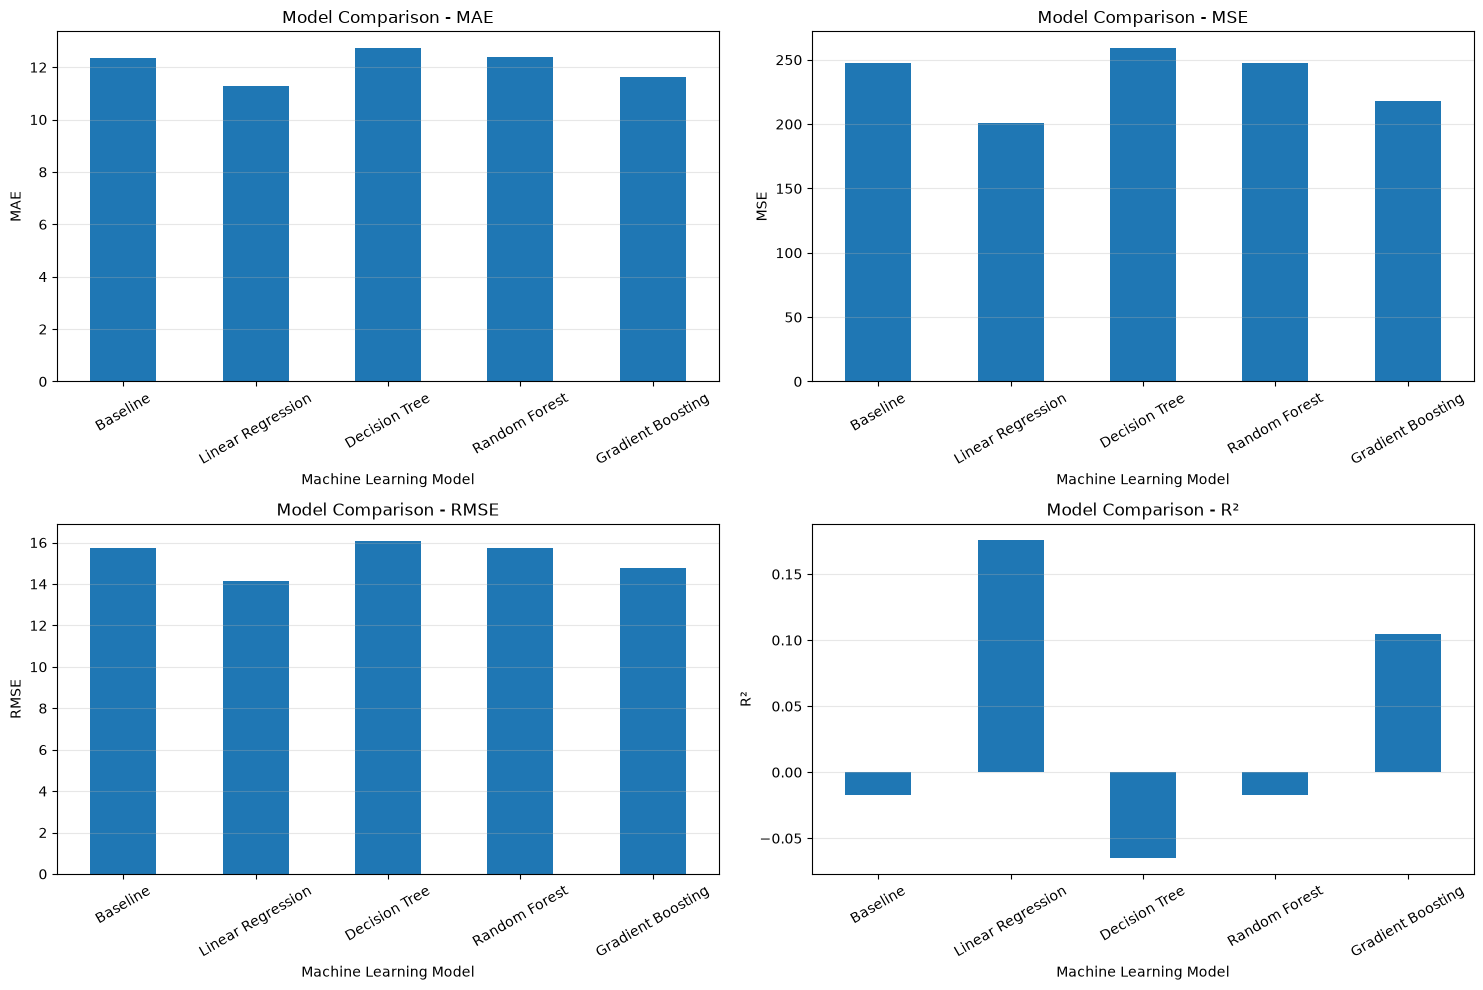

In [1433]:
#  2x2 grid of comparison charts
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

metrics = ['MAE', 'MSE', 'RMSE', 'R²']

for ax, metric in zip(axes.flatten(), metrics):

    results_df.plot(
        x='Model',
        y=metric,
        kind='bar',
        ax=ax,
        legend=False
    )

    ax.set_title(f'Model Comparison - {metric}')
    ax.set_xlabel('Machine Learning Model')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

- Linear Regression achieved the best overall performance, recording the lowest MAE, MSE and RMSE, and the highest R² score (0.176). Gradient Boosting was the second-best model, while Decision Tree and Random Forest performed poorly on unseen data. Overall, none of the models achieved sufficiently strong predictive performance, indicating that the selected features may not contain enough information to accurately predict students' mathematics scores.